In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import glob

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Load processed data from 00_Data_Preprocessing

files = {}

for name in ["X_train", "X_test", "y_train", "y_test"]:
    matches = glob.glob(
        f"/kaggle/input/**/{name}.csv",
        recursive=True
    )

    if not matches:
        raise FileNotFoundError(f"{name}.csv not found!")

    files[name] = matches[0]

X_train = pd.read_csv(files["X_train"]).values
X_test = pd.read_csv(files["X_test"]).values

y_train = pd.read_csv(files["y_train"]).values.ravel()
y_test = pd.read_csv(files["y_test"]).values.ravel()

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Data loaded successfully!
X_train: (8929, 50)
X_test: (2233, 50)
y_train: (8929,)
y_test: (2233,)


In [2]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


print("Sigmoid and Loss functions created successfully!")

Sigmoid and Loss functions created successfully!


In [3]:
def rmsprop(
    X, y,
    learning_rate=0.001,
    epochs=100,
    beta=0.9,
    epsilon=1e-8
):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    cache_w = np.zeros(n_features)
    cache_b = 0.0

    loss_history = []

    for epoch in range(epochs):

        z = np.dot(X, weights) + bias
        y_pred = sigmoid(z)

        dw = np.dot(X.T, (y_pred - y)) / n_samples
        db = np.mean(y_pred - y)

        cache_w = beta * cache_w + (1 - beta) * (dw ** 2)
        cache_b = beta * cache_b + (1 - beta) * (db ** 2)

        weights -= learning_rate * dw / (np.sqrt(cache_w) + epsilon)
        bias -= learning_rate * db / (np.sqrt(cache_b) + epsilon)

        loss = compute_loss(y, sigmoid(np.dot(X, weights) + bias))
        loss_history.append(loss)

    return weights, bias, loss_history


print("RMSprop algorithm created successfully!")

RMSprop algorithm created successfully!


In [4]:
start_time = time.time()

weights_rms, bias_rms, loss_history_rms = rmsprop(
    X_train,
    y_train,
    learning_rate=0.001,
    epochs=100,
    beta=0.9
)

training_time_rms = time.time() - start_time

print("RMSprop Training Completed!")
print("Final Training Loss:", loss_history_rms[-1])
print("Training Time:", round(training_time_rms, 4))

RMSprop Training Completed!
Final Training Loss: 0.6270600588984009
Training Time: 0.1151


In [5]:
def predict(X, weights, bias, threshold=0.5):
    probabilities = sigmoid(np.dot(X, weights) + bias)
    return (probabilities >= threshold).astype(int)


y_pred_rms = predict(X_test, weights_rms, bias_rms)

print("RMSprop Predictions generated successfully!")

RMSprop Predictions generated successfully!


In [6]:
accuracy_rms = accuracy_score(y_test, y_pred_rms)
precision_rms = precision_score(y_test, y_pred_rms)
recall_rms = recall_score(y_test, y_pred_rms)
f1_rms = f1_score(y_test, y_pred_rms)

print("RMSprop Results")
print("------------------------")
print("Accuracy:", round(accuracy_rms, 4))
print("Precision:", round(precision_rms, 4))
print("Recall:", round(recall_rms, 4))
print("F1-Score:", round(f1_rms, 4))
print("Training Time:", round(training_time_rms, 4))

RMSprop Results
------------------------
Accuracy: 0.6744
Precision: 0.6927
Recall: 0.5624
F1-Score: 0.6208
Training Time: 0.1151


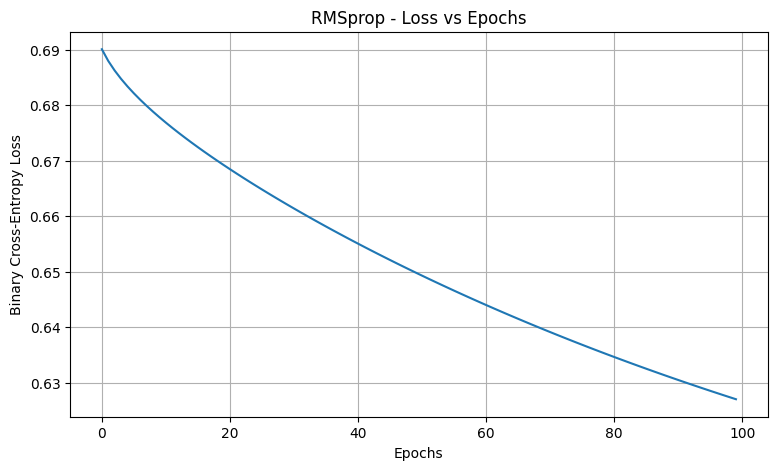

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history_rms)

plt.title("RMSprop - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

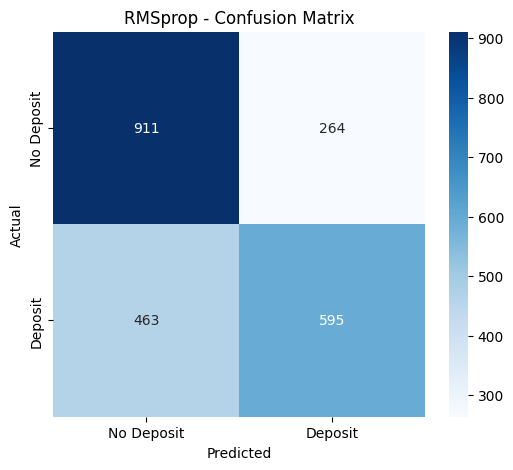

In [8]:
cm = confusion_matrix(y_test, y_pred_rms)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Deposit", "Deposit"],
    yticklabels=["No Deposit", "Deposit"]
)

plt.title("RMSprop - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()